# 00. Data MIT-BIH Arrhythmia Database

**Tujuan.** Menyiapkan data nyata untuk semua uji berikutnya: unduh, cek, resample 360 ke 250 Hz, filter, dan hitung distribusi kelas AAMI pada DS1 (latih) dan DS2 (uji).

**Sumber.** MIT-BIH Arrhythmia Database v1.0.0 (PhysioNet), 48 rekaman sekitar 30 menit, 360 Hz, 11 bit, dua kanal. Lisensi: Open Data Commons Attribution License v1.0. Rujukan lengkap ada di `REFERENSI.md`.

**Keputusan metode.**
- Kanal dipilih dengan `sig_name == 'MLII'`, bukan indeks, karena urutan kanal tidak sama di semua rekaman.
- Rekaman alat pacu jantung (102, 104, 107, 217) dikeluarkan.
- Pembagian antarpasien DS1/DS2 mengikuti de Chazal dkk. (2004). Pemetaan kelas mengikuti pengelompokan AAMI (ANSI/AAMI EC57).
- Resample ke 250 Hz agar sama dengan perangkat ESP32 + AD8232. Posisi anotasi R diskalakan dan dibulatkan.
- Band-pass Butterworth orde 4, 0,5 sampai 40 Hz, zero-phase (`filtfilt`).

## 1. Unduh dan cek berkas

In [2]:
subprocess.run([sys.executable, str(ROOT/"data/download_mitdb.py")], check=True)
dat = sorted(mitdb.RAW.glob("*.dat"))
assert len(dat) == 48, len(dat)
all_ids = sorted(int(p.stem) for p in dat)
assert set(mitdb.DS1).isdisjoint(mitdb.DS2)
assert set(mitdb.DS1 + mitdb.DS2 + mitdb.EXCLUDE) == set(all_ids), "DS1+DS2+pacu harus = 48 rekaman"
print(f"{len(all_ids)} rekaman; DS1={len(mitdb.DS1)}, DS2={len(mitdb.DS2)}, dikeluarkan={mitdb.EXCLUDE}")

48 rekaman di /Users/yutaaa/Developments/benchmark-ekg/data/raw
48 rekaman; DS1=22, DS2=22, dikeluarkan=[102, 104, 107, 217]


## 2. Urutan kanal tiap rekaman

Tabel ini menunjukkan alasan memilih kanal dengan nama. Baris dengan `mlii_idx` bukan 0 akan salah kalau kanal diambil dengan indeks 0.

In [3]:
import wfdb
rows = []
for rid in all_ids:
    h = wfdb.rdheader(str(mitdb.RAW/str(rid)))
    rows.append({"rekaman": rid, "kanal": "/".join(h.sig_name), "mlii_idx": h.sig_name.index("MLII") if "MLII" in h.sig_name else -1,
                 "fs": h.fs, "durasi_menit": round(h.sig_len/h.fs/60, 1)})
ch = pd.DataFrame(rows); ch.to_csv(ROOT/"results/00_kanal.csv", index=False)
print("Rekaman tanpa MLII:", ch[ch.mlii_idx < 0].rekaman.tolist())
print("Rekaman dengan MLII bukan kanal 0:", ch[ch.mlii_idx > 0].rekaman.tolist())
ch[ch.mlii_idx != 0]

Rekaman tanpa MLII: [102, 104]
Rekaman dengan MLII bukan kanal 0: [114]


,rekaman,kanal,mlii_idx,fs,durasi_menit
2,102,V5/V2,-1,360,30.1
4,104,V5/V2,-1,360,30.1
13,114,V5/MLII,1,360,30.1


## 3. Muat semua rekaman (250 Hz, terfilter)

Rekaman tanpa MLII, kalau ada, dilaporkan di atas dan tidak dipakai. Rekaman alat pacu dikeluarkan.

In [4]:
use = [r for r in all_ids if r not in mitdb.EXCLUDE]
recs = {r: mitdb.load(r) for r in use}
rows = [{"rekaman": r, "set": "DS1" if r in mitdb.DS1 else "DS2", "durasi_detik": round(len(d["x"])/mitdb.FS, 1),
         "n_detak": len(d["r"])} for r, d in recs.items()]
meta = pd.DataFrame(rows); meta.to_csv(ROOT/"results/00_rekaman.csv", index=False)
meta.groupby("set").agg(rekaman=("rekaman", "count"), detak=("n_detak", "sum"), jam=("durasi_detik", lambda s: round(s.sum()/3600, 2)))

,rekaman,detak,jam
set,,,
DS1,22,51021,11.03
DS2,22,49712,11.03


## 4. Visualisasi sinyal: mentah 360 Hz, resample 250 Hz, terfilter

Rekaman 100, 10 detik. Garis vertikal putus-putus adalah anotasi R (setelah penyesuaian posisi ke 250 Hz).

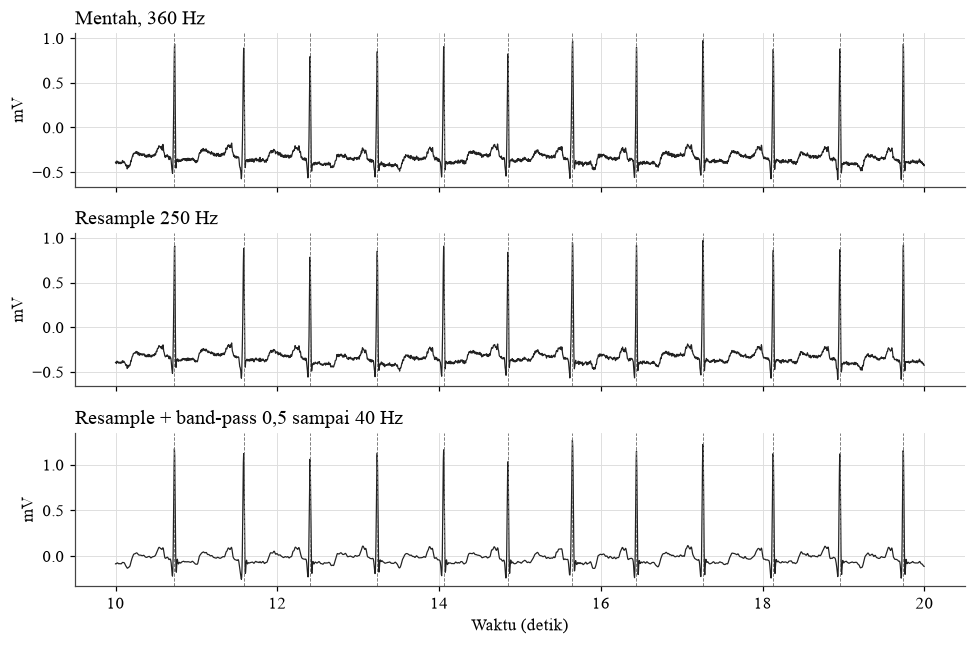

In [5]:
import wfdb
rid = 100; t0, T = 10, 10
rec = wfdb.rdrecord(str(mitdb.RAW/str(rid))); ci = rec.sig_name.index("MLII")
raw = rec.p_signal[:, ci]
d_raw = mitdb.load(rid, filt=False); d_f = mitdb.load(rid)
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(np.arange(t0*360, (t0+T)*360)/360, raw[t0*360:(t0+T)*360], color="#222", lw=.8); ax[0].set_title("Mentah, 360 Hz", loc="left")
ax[1].plot(np.arange(t0*250, (t0+T)*250)/250, d_raw["x"][t0*250:(t0+T)*250], color="#222", lw=.8); ax[1].set_title("Resample 250 Hz", loc="left")
ax[2].plot(np.arange(t0*250, (t0+T)*250)/250, d_f["x"][t0*250:(t0+T)*250], color="#222", lw=.8); ax[2].set_title("Resample + band-pass 0,5 sampai 40 Hz", loc="left")
rs = d_f["r"][(d_f["r"] >= t0*250) & (d_f["r"] < (t0+T)*250)]/250
for a in ax:
    for r in rs: a.axvline(r, color="#777", ls="--", lw=.6)
    a.set_ylabel("mV")
ax[2].set_xlabel("Waktu (detik)"); fig.tight_layout(); fig.savefig(ROOT/"grafik/00_sinyal.png"); plt.show()

## 5. Spektrum dan perbedaan frekuensi listrik

MIT-BIH direkam di Amerika Serikat (listrik 60 Hz). Perangkat kita di Indonesia (listrik 50 Hz). Band-pass atas 40 Hz berada di bawah 50 dan 60 Hz, jadi satu filter ini meredam keduanya. Grafik menunjukkan rapat daya sebelum dan sesudah filter pada beberapa rekaman, dengan penanda 50 Hz dan 60 Hz.

Konsekuensi yang harus dicatat: model dilatih pada derau jaringan 60 Hz, tetapi karena sudah difilter, komponen 50/60 Hz seharusnya hilang pada kedua kondisi. Ini belum dibuktikan pada data perangkat nyata (AD8232 dengan derau lain, resolusi ADC 12 bit, elektroda berbeda).

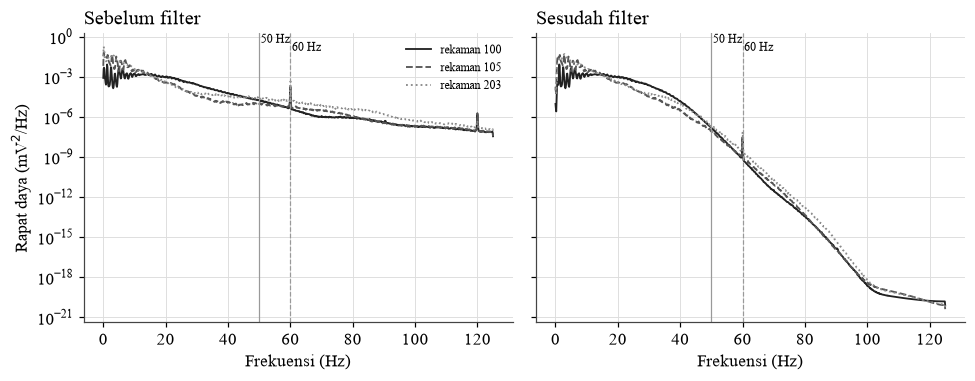

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for k, rid in enumerate([100, 105, 203]):
    for a, filt in zip(ax, [False, True]):
        x = mitdb.load(rid, filt=filt)["x"]
        f, p = welch(x, fs=250, nperseg=2048)
        a.semilogy(f, p, label=f"rekaman {rid}", color=GRAYS[k], ls=["-", "--", ":"][k], lw=1.2)
for a, ttl in zip(ax, ["Sebelum filter", "Sesudah filter"]):
    for fq, ls in [(50, "-"), (60, "--")]: a.axvline(fq, color="#999", ls=ls, lw=.8)
    a.text(50.5, a.get_ylim()[1]*.2, "50 Hz", fontsize=8); a.text(60.5, a.get_ylim()[1]*.05, "60 Hz", fontsize=8)
    a.set_title(ttl, loc="left"); a.set_xlabel("Frekuensi (Hz)")
ax[0].set_ylabel("Rapat daya (mV$^2$/Hz)"); ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(ROOT/"grafik/00_spektrum.png"); plt.show()

## 6. Cek posisi R setelah resample

Posisi R dari anotasi dibulatkan ke grid 250 Hz, jadi galat maksimum penskalaan adalah setengah sampel (2 ms). Untuk memastikan tidak ada pergeseran sistematis, dihitung jarak antara anotasi dan puncak lokal terdekat pada sinyal terfilter (jendela plus minus 40 ms), lalu dibandingkan dengan jarak yang sama di sinyal 360 Hz asli. Anotasi MIT-BIH tidak selalu tepat di puncak, jadi yang penting adalah selisih antar-resolusi, bukan nol.

In [7]:
def off(x, pos, fs, w_ms=40):
    w = int(fs*w_ms/1000); o = []
    for p in pos[(pos > w) & (pos < len(x)-w)]:
        seg = np.abs(x[p-w:p+w+1] - np.median(x[p-w:p+w+1])); o.append((np.argmax(seg)-w)/fs*1000)
    return np.array(o)
rows = []
for rid in [100, 106, 119, 200, 208, 233]:
    rec = wfdb.rdrecord(str(mitdb.RAW/str(rid))); ci = rec.sig_name.index("MLII")
    ann = wfdb.rdann(str(mitdb.RAW/str(rid)), "atr")
    o360 = off(rec.p_signal[:, ci], ann.sample, 360)
    d = mitdb.load(rid); o250 = off(d["x"], d["r"], 250)
    rows.append({"rekaman": rid, "median_360_ms": np.median(o360), "median_250_ms": np.median(o250),
                 "selisih_ms": np.median(o250)-np.median(o360)})
chk = pd.DataFrame(rows).round(2); chk.to_csv(ROOT/"results/00_cek_posisi_R.csv", index=False)
chk

,rekaman,median_360_ms,median_250_ms,selisih_ms
0,100,2.78,0.0,-2.78
1,106,0.00,0.0,0.00
2,119,0.00,0.0,0.00
3,200,2.78,4.0,1.22
4,208,0.00,0.0,0.00
5,233,0.00,0.0,0.00


## 7. Distribusi kelas AAMI pada DS1 dan DS2

In [8]:
rows = []
for r, d in recs.items():
    s = "DS1" if r in mitdb.DS1 else "DS2"
    for c in mitdb.CLASSES: rows.append({"rekaman": r, "set": s, "kelas": c, "n": int((d["y"] == c).sum())})
dist = pd.DataFrame(rows); dist.to_csv(ROOT/"results/00_distribusi_kelas.csv", index=False)
tab = dist.pivot_table(index="set", columns="kelas", values="n", aggfunc="sum")[mitdb.CLASSES]
tab["total"] = tab.sum(axis=1); pct = (tab[mitdb.CLASSES].div(tab["total"], axis=0)*100).round(2)
print("Jumlah detak"); display(tab); print("Persen"); display(pct)

Jumlah detak


kelas,N,S,V,F,Q,total
set,,,,,,
DS1,45866,944,3788,415,8,51021
DS2,44259,1837,3221,388,7,49712


Persen


kelas,N,S,V,F,Q
set,,,,,
DS1,89.90,1.85,7.42,0.81,0.02
DS2,89.03,3.70,6.48,0.78,0.01


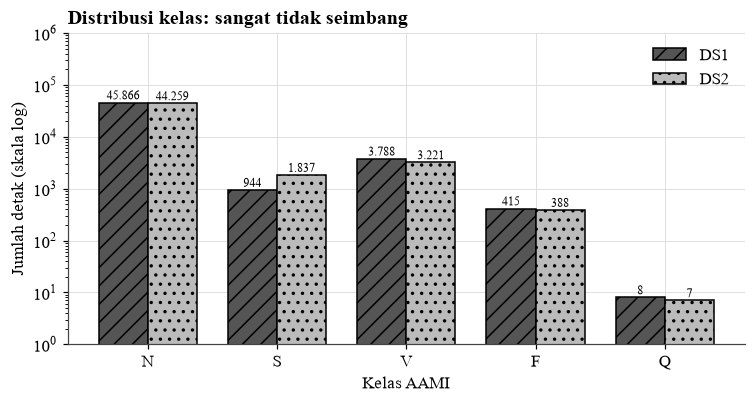

In [9]:
dist = pd.read_csv(ROOT/"results/00_distribusi_kelas.csv")  # grafik dibuat dari CSV
t = dist.pivot_table(index="set", columns="kelas", values="n", aggfunc="sum")[mitdb.CLASSES]
fig, ax = plt.subplots(figsize=(7, 3.8)); w = .38; x = np.arange(5)
for k, (s, hatch) in enumerate([("DS1", "//"), ("DS2", "..")]):
    b = ax.bar(x + (k-.5)*w, t.loc[s].values, w, color=["#555", "#bbb"][k], edgecolor="#000", hatch=hatch, label=s)
    for xi, v in zip(x + (k-.5)*w, t.loc[s].values): ax.text(xi, v*1.15, f"{v:,}".replace(",", "."), ha="center", fontsize=8)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(mitdb.CLASSES); ax.set_ylim(1, 1e6)
ax.set_xlabel("Kelas AAMI"); ax.set_ylabel("Jumlah detak (skala log)"); ax.legend(frameon=False)
ax.set_title("Distribusi kelas: sangat tidak seimbang", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(ROOT/"grafik/00_distribusi_kelas.png"); plt.show()

## 8. Simpan data olahan untuk notebook 01 sampai 04

In [10]:
out = ROOT/"data/processed"; out.mkdir(exist_ok=True)
np.savez_compressed(out/"mitdb_250hz.npz", **{f"x_{r}": d["x"].astype("float32") for r, d in recs.items()},
                    **{f"r_{r}": d["r"] for r, d in recs.items()}, **{f"y_{r}": d["y"] for r, d in recs.items()})
print("tersimpan:", round((out/"mitdb_250hz.npz").stat().st_size/2**20, 1), "MB")

tersimpan: 70.4 MB


## Kesimpulan notebook 00

Ringkasan angka ada di tabel bagian 7. Catatan yang harus dibawa ke notebook lain:
- Kelas S, V, F, Q jauh lebih jarang dari N, dan DS1 dan DS2 tidak punya proporsi yang sama. Akurasi keseluruhan akan menyesatkan, jadi dipakai sensitivitas, positive predictivity, dan F1 per kelas.
- Filter zero-phase (`filtfilt`) hanya bisa dipakai pada jendela yang sudah terkumpul. Untuk 10 detik per jendela itu wajar, tetapi tepi jendela terkena efek ujung. Penanganannya di `app_reference/inference.py`.
- Data hanya dari 47 subjek, direkam di AS dengan perangkat berbeda dari AD8232. Hasil di sini bukan bukti performa pada perangkat kita.